## Importation des données

In [1]:
import requests
import pandas as pd

# Fonction permettant de récupérer les données sur l'API de l'ADEME
def get_dpe(type):
    if type == "existant":
        url = "https://data.ademe.fr/data-fair/api/v1/datasets/dpe03existant/lines"
    elif type == "neuf":
        url = "https://data.ademe.fr/data-fair/api/v1/datasets/dpe02neuf/lines"
    else:
        print("Type de logement introuvable")
        return None

    params = {
        "qs": "code_region_ban:94", # On se base dans la région CORSE
        "size": "500"
    }

    toutes_les_lignes = []

    while url:       
        response = requests.get(url, params=params)
        data = response.json()

        # Pour afficher le nombre total de ligne à scrapper 
        if params != None :
            print(f"Nombre total de ligne : {data.get('total')}")

        toutes_les_lignes.extend(data["results"])

        print(f"Nombre de lignes faites : {len(toutes_les_lignes)}")

        url = data.get("next")

        params = None

    df = pd.DataFrame(toutes_les_lignes)
    df.to_csv(f"Data/dpe_{type}.csv", index=False, encoding="utf-8")
    return df

In [2]:
import os
os.chdir("../")

In [3]:
#Importation des nouveaux logements
if not os.path.exists("Data/dpe_neuf.csv") :
    dpe_neuf = get_dpe("neuf")
else :
    dpe_neuf = pd.read_csv("Data/dpe_neuf.csv", header=0, encoding="utf-8", low_memory=False)

#Importation des logements existant
if not os.path.exists("Data/dpe_existant.csv") :
    dpe_existant = get_dpe("existant")
else :
    dpe_existant = pd.read_csv("Data/dpe_existant.csv", header=0, encoding="utf-8", low_memory=False)

### Fusion des deux dataframe pour en avoir qu'un seul avec ajout de variable importante

In [4]:
dpe_neuf = dpe_neuf.assign(logement="neuf", annee_construction=2026)
dpe_existant["logement"] = "ancien"

column_commune = dpe_neuf.columns.intersection(dpe_existant.columns)

data = pd.concat([dpe_neuf.loc[:,column_commune],dpe_existant.loc[:,column_commune]], ignore_index=True)
data.shape

C:\Users\nijim\AppData\Local\Temp\ipykernel_32136\1875382000.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dpe_existant["logement"] = "ancien"


(59570, 175)

### Passage du numero_dpe en index de dataframe

In [5]:
data.index = data["numero_dpe"]
data = data.drop(columns="numero_dpe")
data.shape

(59570, 174)

### Suppréssions des variables considéré comme inutile

Note : se référé au code de la partie data pour celà

In [6]:
variable_a_suppr = []
with open("Data/variable_a_suppr.txt", "r", encoding="utf-8") as f:
    liste = f.readlines()
    for x in liste:
        x = x.removesuffix("\n")
        if x in data.columns:
            variable_a_suppr.append(x)
print(variable_a_suppr)

['date_derniere_modification_dpe', 'date_visite_diagnostiqueur', 'date_etablissement_dpe', 'date_reception_dpe', 'date_fin_validite_dpe', 'numero_dpe_remplace', 'numero_dpe_immeuble_associe', 'id_rnb', 'provenance_id_rnb', 'modele_dpe', 'version_dpe', 'methode_application_dpe', 'besoin_chauffage', 'besoin_ecs', 'besoin_refroidissement', 'cout_total_5_usages', 'cout_chauffage', 'cout_ecs', 'cout_refroidissement', 'cout_eclairage', 'cout_auxiliaires', 'type_energie_n1', 'conso_5_usages_ef_energie_n1', 'conso_chauffage_ef_energie_n1', 'conso_ecs_ef_energie_n1', 'cout_total_5_usages_energie_n1', 'cout_chauffage_energie_n1', 'cout_ecs_energie_n1', 'emission_ges_5_usages_energie_n1', 'emission_ges_chauffage_energie_n1', 'emission_ges_ecs_energie_n1', 'type_energie_n2', 'conso_5_usages_ef_energie_n2', 'conso_chauffage_ef_energie_n2', 'conso_ecs_ef_energie_n2', 'cout_total_5_usages_energie_n2', 'cout_chauffage_energie_n2', 'cout_ecs_energie_n2', 'emission_ges_5_usages_energie_n2', 'emission_ge

In [7]:
data = data.drop(columns=variable_a_suppr)
data.shape

(59570, 106)

### Mise de coté des variables cibles et illustrative

Note : Là aussi, se référé au code de la partie Data

In [8]:
variable_cible = []
with open("Data/variable_cible.txt", "r", encoding="utf-8") as f:
    liste = f.readlines()
    for x in liste:
        x = x.removesuffix("\n")
        if x in data.columns:
            variable_cible.append(x)
print(variable_cible)

['etiquette_dpe', 'etiquette_ges', 'conso_5_usages_ep', 'conso_5_usages_par_m2_ep', 'conso_chauffage_ep', 'conso_ecs_ep', 'conso_refroidissement_ep', 'conso_eclairage_ep', 'conso_auxiliaires_ep', 'conso_5_usages_ef', 'conso_5_usages_par_m2_ef', 'conso_chauffage_ef', 'conso_ecs_ef', 'conso_refroidissement_ef', 'conso_eclairage_ef', 'conso_auxiliaires_ef']


In [9]:
Y = data.loc[:,variable_cible]
print(Y.shape)

(59570, 16)


In [10]:
data = data.drop(columns=variable_cible)
data.shape

(59570, 90)

In [11]:
ILLU = data.filter(regex="coordonnee_cartographique_")
print(ILLU.shape)

(59570, 2)


In [12]:
data = data.drop(columns=ILLU.columns)
print(data.shape)

(59570, 88)


A cette étape nous avons 3 dataframe :

- data -> comporte les potentielles variable explicative qui vont passé par plusieurs étape de vérification
- Y -> comporte nos variable cible (les étiquêtes DPE et la consomation)
- ILLU -> comporte les variables de localisation

## Vérification des types des variables

In [13]:
#Variable booléenne
#Si min = 0 et max = 1 -> c'est du booléen
min0 = data.min()==0
max1 = data.max()==1

bool_cols = data.columns[min0 & max1]

data[bool_cols] = data[bool_cols].astype(bool)

data.select_dtypes(include="bool").info()

<class 'pandas.DataFrame'>
Index: 59570 entries, 2620N0025074S to 2620E2590403W
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   ventilation_posterieure_2012   59570 non-null  bool 
 1   appartement_non_visite         59570 non-null  bool 
 2   presence_brasseur_air          59570 non-null  bool 
 3   isolation_toiture              59570 non-null  bool 
 4   protection_solaire_exterieure  59570 non-null  bool 
 5   logement_traversant            59570 non-null  bool 
 6   inertie_lourde                 59570 non-null  bool 
dtypes: bool(7)
memory usage: 1.6 MB


## Sélection de variables

In [14]:
col_a_sup = [] # Pour garder toutes les variables à supprimé

### Variable avec trop de valeurs manquantes

In [15]:
# Si plus de 50% de valeurs manquantes -> On supprime
na = data.columns[(data.isna().sum()*100/data.shape[0])>=50]

col_a_sup.extend(na)
print(len(na))

24


### Suppréssion des variables unique par dpe OU identique pour tout les dpe

In [16]:
#Si la variable est identique partout
identique = data.nunique()==1
not_this_col = data.columns[identique] #On récupère son nom
col_a_sup.extend(not_this_col)
print("Identiques : ",not_this_col)

#Si la variable est différente partout
unique = data.nunique()==data.shape[0]
not_this_col = data.columns[unique] #On récupère son nom
col_a_sup.extend(not_this_col)
print("Unique : ", not_this_col)

Identiques :  Index([], dtype='str')
Unique :  Index(['_i', '_id'], dtype='str')


### Suppréssion des variables qualitatives avec trop de modalité

In [17]:
import numpy as np
print(np.sort(data.select_dtypes(include="str").nunique())) 

[    2     2     2     2     3     3     3     3     3     3     3     3
     4     4     4     4     4     4     4     4     4     5     6     7
     8     8     9    10    10    10    10    11    13    17    31    38
    44    57    71    79    85    85   106   112   117   508   927  2107
 14705 59570]


Notre objectif étant de réduire drastiquement le nombre de variable (au vue d'un remplissage de formulaire par les utilisateurs), nous allons nous arrêter à 13 modalités pour une variable qualitative. 

In [18]:
trop_quali = data.select_dtypes(include="str").nunique()>17

col_a_sup.extend(data.select_dtypes(include="str").columns[trop_quali])
print(sum(trop_quali))

16


### Supprésion des variables avec une trop faible variance 

#### Variable numérique

In [19]:
from sklearn.feature_selection import VarianceThreshold
thresholder_num = VarianceThreshold(threshold=0.5)
thresholder_num.fit_transform(data.select_dtypes(include=["float","int"]))

col_a_sup.extend(data.select_dtypes(include=["float","int"]).columns[~thresholder_num.get_support()]) 
print(len(data.select_dtypes(include=["float","int"]).columns[~thresholder_num.get_support()]))

1


c:\Users\nijim\Documents\GitHub\Machine-Learning-sous-Python\.venv\Lib\site-packages\sklearn\feature_selection\_variance_threshold.py:114: RuntimeWarning: Degrees of freedom <= 0 for slice.
  self.variances_ = np.nanvar(X, axis=0)


#### Variable binaire

In [20]:
# Var(x) = p(1-p), ici p = 75%, on supprime alors toutes les variables binaires 
# qui ont une catégorie avec 75% ou plus d'observation (et donc une plus faible)

# Source : Guide pratique du machine learning avec Python, chapitre 10 p.198
thresholder_bool = VarianceThreshold(threshold=0.75*(1-0.75)) 
thresholder_bool.fit_transform(data.select_dtypes(include="bool"))

col_a_sup.extend(data.select_dtypes(include="bool").columns[~thresholder_bool.get_support()]) 
print(len(data.select_dtypes(include="bool").columns[~thresholder_bool.get_support()]))

3


### Traitement des caractéristiques fortement corrélées

In [21]:
import numpy as np

#Matrice de corrélation
corr_matrix = data.select_dtypes(include=["int","float"]).corr().abs()

#On récupère que la diagonale supérieur (car la matrice est symétrique, un seul coté suffit)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape),
                                   k=1).astype(bool))

#On cherche les colones qui ont plus de 90% de corrélation avec une autre variable
to_drop = [col for col in upper.columns if any(upper[col] > 0.90)]

col_a_sup.extend(to_drop)
print(len(to_drop))

10


### Netoyage des colones à supprimer

In [22]:
col_a_sup = set(col_a_sup) # pour retirer les doublons

print(len(col_a_sup))
print(col_a_sup)

45
{'usage_generateur_n2_installation_n1', 'description_installation_ecs_n1', 'description_generateur_n1_ecs_n1', 'type_generateur_n2_installation_n1', '_geopoint', 'type_ventilation', 'surface_habitable_immeuble', 'surface_climatisee', 'type_installation_chauffage_n2', 'surface_chauffee_installation_chauffage_n2', 'type_generateur_froid', 'usage_generateur_n1_installation_n2', 'deperditions_ponts_thermiques', 'conso_chauffage_installation_chauffage_n1', 'description_installation_chauffage_n1', 'type_generateur_chauffage_principal', 'surface_tertiaire_immeuble', 'type_energie_generateur_n1_installation_n2', '_id', 'surface_chauffee_installation_chauffage_n1', 'type_energie_generateur_n2_installation_n1', 'ventilation_posterieure_2012', 'description_generateur_froid', 'categorie_enr', 'deperditions_renouvellement_air', 'nombre_niveau_immeuble', 'surface_habitable_desservie_par_installation_ecs_n1', 'configuration_installation_chauffage_n2', 'surface_ventilee', 'description_installation_

In [23]:
data = data.drop(columns=col_a_sup)
print(data.shape)

(59570, 43)


In [24]:
#A servi à analysé les colones restantes
for col in data.columns:
    print(f"----{col}----")
    print(data[col], "\n")

----configuration_installation_chauffage_n1----
numero_dpe
2620N0025074S    Installation de chauffage simple
2620N0011394O                                 NaN
2420N3326336G                                 NaN
2420N0067785J                                 NaN
2120N0386025G                                 NaN
                               ...               
2620E2293727G    Installation de chauffage simple
2620E2378054P    Installation de chauffage simple
2620E2410950V    Installation de chauffage simple
2620E2547824F    Installation de chauffage simple
2620E2590403W    Installation de chauffage simple
Name: configuration_installation_chauffage_n1, Length: 59570, dtype: str 

----deperditions_murs----
numero_dpe
2620N0025074S      21.5
2620N0011394O       NaN
2420N3326336G       NaN
2420N0067785J       NaN
2120N0386025G      29.6
                  ...  
2620E2293727G    2979.9
2620E2378054P       4.2
2620E2410950V      16.8
2620E2547824F       8.8
2620E2590403W       8.6
Name: deperditi

numero_dpe
2620N0025074S     97.0
2620N0011394O     83.4
2420N3326336G    161.7
2420N0067785J     48.4
2120N0386025G      NaN
                 ...  
2620E2293727G      NaN
2620E2378054P     19.1
2620E2410950V     43.0
2620E2547824F     37.1
2620E2590403W     47.7
Name: surface_habitable_logement, Length: 59570, dtype: float64 

----type_installation_ecs_n1----
numero_dpe
2620N0025074S      installation collective
2620N0011394O                          NaN
2420N3326336G                          NaN
2420N0067785J                          NaN
2120N0386025G                          NaN
                           ...            
2620E2293727G    installation individuelle
2620E2378054P    installation individuelle
2620E2410950V    installation individuelle
2620E2547824F    installation individuelle
2620E2590403W    installation individuelle
Name: type_installation_ecs_n1, Length: 59570, dtype: str 

----nombre_logements_desservis_par_installation_ecs_n1----
numero_dpe
2620N0025074S    1.0
26

On retire toutes les variables que l'utilisateurs peut ne pas avoir

In [25]:
a_retirer = data.filter(regex="^_|deperditions_|_n1|annee_construction|ubat_w_par_m2_k|production_electricite_pv_kwhep_par_an").columns.tolist()
# On enlève, dans l'ordre de la regex
    # La variable _rang (commence par _)
    # Les variable de deperditions (information inconnue)
    # Les variable relative au n1 (présence de _n1 à la fin)
    # L'année de construction (trop de valeur manquante et on possède periode de construction pour toutes les données)
    # ubat_w_par_m2_k (information pas en main d'un utilisateur lambda)
    # production_electricite_pv_kwhep_par_an (information pas en main d'un utilisateur lambda)

print(len(a_retirer))

20


In [26]:
data = data.drop(columns=a_retirer)

print(data.shape)

(59570, 23)


A cette étape, il nous reste 23 variables explicatives.

On a pu drastiquement en réduire le nombre mais, pour remplir un questionnaire, celà reste beaucoup.

### Imputation des données manquantes

In [27]:
for col in data.columns:
    try:
        data[col] = data[col].fillna(data[col].median()) #Imputation par la médiane des variables quanti
    except:
        try:
            data[col] = data[col].fillna("Inconnue") #Imputation par une nouvelle catégorie "Inconnue"
        except:
            print(f"Erreur sur la colonne {col}")

### Supprimer les caractéristiques inutiles à la classification

In [28]:
# On sépare la variable cible des variables explicatives catégorielle d'un coté, quantitative de l'autre
XQuali = data.select_dtypes(include=["str","bool"])
XQuali_encoded = pd.get_dummies(XQuali, dtype=int)
XQuanti = data.select_dtypes(exclude=["str","bool"])

print(XQuali.shape)
print(XQuanti.shape)

(59570, 19)
(59570, 4)


In [29]:
print(XQuali.columns)

Index(['qualite_isolation_menuiseries', 'qualite_isolation_plancher_bas',
       'qualite_isolation_enveloppe', 'type_energie_principale_ecs',
       'classe_inertie_batiment', 'type_batiment', 'periode_construction',
       'zone_climatique', 'qualite_isolation_murs', 'classe_altitude',
       'type_energie_principale_chauffage', 'indicateur_confort_ete',
       'presence_brasseur_air', 'isolation_toiture', 'logement_traversant',
       'inertie_lourde', 'type_installation_chauffage',
       'type_installation_ecs', 'logement'],
      dtype='str')


#### Variable quantitative

In [30]:
from sklearn.feature_selection import SelectFwe, f_classif

sel = SelectFwe(f_classif, alpha=0.001) # Si significativité de + de 95%, on sélectionne
sel.fit(XQuanti, Y["etiquette_dpe"])


SelectFwe(alpha=0.001)

In [31]:
XQuanti.columns[sel.pvalues_ < 0.001]
#Toute les variables quantitative se révèle correlé suffisament à la cible, nous pouvons les garder.

Index(['nombre_niveau_logement', 'surface_habitable_logement',
       'hauteur_sous_plafond', 'nombre_appartement'],
      dtype='str')

#### Variable qualitative

In [32]:
from sklearn.feature_selection import chi2

chi2_selector = SelectFwe(chi2, alpha=0.05)
XQuali_kbest = chi2_selector.fit_transform(XQuali_encoded, Y["etiquette_dpe"])

XQuali_kbest

array([[1, 1, 1, ..., 0, 0, 1],
       [1, 1, 1, ..., 0, 0, 1],
       [1, 1, 1, ..., 0, 0, 1],
       ...,
       [0, 0, 0, ..., 0, 1, 0],
       [0, 0, 1, ..., 0, 1, 0],
       [0, 0, 1, ..., 0, 1, 0]], shape=(59570, 83))

In [33]:
colonnes_selectionnees = XQuali_encoded.columns[chi2_selector.get_support()]

# On va récupéré les vrais nom des colones :
vrai_col= []
for col in colonnes_selectionnees :
    if col not in XQuali.columns:
        col = col.split("_")[:-1] #On enlève le rajout du get dummies
        col ="_".join(col)
        if col not in vrai_col:
            vrai_col.append(col)

print(len(vrai_col))

15


In [34]:
XQuali = XQuali.loc[:,vrai_col]
XQuali.shape

(59570, 15)

#### On regroupe tout

In [35]:
df = pd.concat([XQuali, XQuanti], axis=1)
df.shape

(59570, 19)

## Gestion des valeurs manquantes (variables cibles / Illustrative)

In [36]:
print(np.sum(Y.isna())) 
# 7 valeurs manquantes -> on va supprimé les individus qui ont ses valeurs manquantes

index_manquants = Y[Y.isna().any(axis=1)].index
print(index_manquants) #Un seul individus à supprimé dans les 3 dataframes

7
Index(['2120E0107823V'], dtype='str', name='numero_dpe')


In [37]:
Y = Y.drop(index=index_manquants)
ILLU = ILLU.drop(index=index_manquants)
df = df.drop(index=index_manquants)

In [38]:
print(np.sum(ILLU.isna())) #Aucune valeurs manquante, on passe !

0


In [39]:
#Imputation dans les données explicative déjà faite, on revérifie par principe
print(np.sum(df.isna())) 

0


## Suppression des outliers

In [40]:
index_suppr = [] #Pour y faire d'un coup sur les index de Y et ILLU

In [41]:
df.info()

<class 'pandas.DataFrame'>
Index: 59569 entries, 2620N0025074S to 2620E2590403W
Data columns (total 19 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   qualite_isolation_menuiseries      59569 non-null  str    
 1   qualite_isolation_plancher_bas     59569 non-null  str    
 2   qualite_isolation_enveloppe        59569 non-null  str    
 3   type_energie_principale_ecs        59569 non-null  str    
 4   classe_inertie_batiment            59569 non-null  str    
 5   type_batiment                      59569 non-null  str    
 6   periode_construction               59569 non-null  str    
 7   zone_climatique                    59569 non-null  str    
 8   qualite_isolation_murs             59569 non-null  str    
 9   classe_altitude                    59569 non-null  str    
 10  type_energie_principale_chauffage  59569 non-null  str    
 11  indicateur_confort_ete             59569 non-null 

### Variable qualitative

In [42]:
for x in df.select_dtypes(include="str").columns:
    print(df[x].value_counts(), "\n\n")

qualite_isolation_menuiseries
moyenne         27911
insuffisante    14355
très bonne       9782
bonne            7521
Name: count, dtype: int64 


qualite_isolation_plancher_bas
très bonne      21509
insuffisante    17578
bonne           10376
moyenne          5608
Inconnue         4498
Name: count, dtype: int64 


qualite_isolation_enveloppe
insuffisante    31148
bonne           10511
moyenne         10430
très bonne       7480
Name: count, dtype: int64 


type_energie_principale_ecs
Électricité                                39169
Gaz naturel                                 9452
Non affecté                                 7246
GPL                                         2783
Fioul domestique                             368
Réseau de Chauffage urbain                   326
Propane                                      175
Butane                                        36
Bois – Bûches                                 10
Bois – Granulés (pellets) ou briquettes        4
Name: count, dtype: 

qualite_isolation_murs
insuffisante    26723
bonne           12705
très bonne      12114
moyenne          8025
Inconnue            2
Name: count, dtype: int64 


classe_altitude
inférieur à 400m    54546
400-800m             3488
Inconnue             1307
supérieur à 800m      228
Name: count, dtype: int64 


type_energie_principale_chauffage
Électricité                                                     43955
Gaz naturel                                                      9699
GPL                                                              2577
Bois – Bûches                                                    1852
Fioul domestique                                                  534
Réseau de Chauffage urbain                                        421
Propane                                                           195
Bois – Granulés (pellets) ou briquettes                           184
Non affecté                                                       118
Butane                   

On remarque que certaine modalité de certaines variable sont très faiblement représenté

On a choisi de regroupé les modalité avec - de 2% dedans par une catégorie "Autre"

In [43]:
for x in df.select_dtypes(include=["str"]).columns:

    frequences = df[x].value_counts(normalize=True)

    modalites_rares = frequences[frequences<0.02].index.tolist()

    #Suppression des individus avec "Inconnue" si cette modalité est rare
    if "Inconnue" in modalites_rares:
        ind = df[df[x] == "Inconnue"].index
        print(f"{x} : {len(ind)} individus supprimés (Inconnue)")
        index_suppr.extend(ind.tolist())
        df = df.drop(index=ind)

        #Recalcule des fréquences
        frequences = df[x].value_counts(normalize=True)
        modalites_rares = frequences[frequences < 0.05].index.tolist()

    #Regroupement des modalités rares
    if len(modalites_rares) > 1:
        df[x] = df[x].replace(modalites_rares, "Autre")

    #Suppression d'une seule modalité rare, sauf "Autre"
    elif len(modalites_rares) == 1 and modalites_rares[0] != "Autre":
        ind = df[df[x] == modalites_rares[0]].index
        print(f"{x} : {len(ind)} individus supprimés ({modalites_rares[0]})")
        index_suppr.extend(ind.tolist())
        df = df.drop(index=ind)


    modalite = df[x].value_counts(normalize=True).index.tolist()

    #Si inconnue et autre cohexite, regroupé sous Autre
    if "Inconnue" in modalite and "Autre" in modalite:
        df[x] = df[x].replace("Inconnue", "Autre")

qualite_isolation_murs : 2 individus supprimés (Inconnue)
classe_altitude : 228 individus supprimés (supérieur à 800m)
indicateur_confort_ete : 458 individus supprimés (Non affecté)
type_installation_chauffage : 832 individus supprimés (mixte (collectif-individuel))
type_installation_ecs : 33 individus supprimés (mixte (collectif-individuel))


In [44]:
for x in df.select_dtypes(include="str").columns:
    print(df[x].value_counts(normalize=True), "\n\n")

qualite_isolation_menuiseries
moyenne         0.470163
insuffisante    0.241882
très bonne      0.160714
bonne           0.127241
Name: proportion, dtype: float64 


qualite_isolation_plancher_bas
très bonne      0.360607
insuffisante    0.293971
bonne           0.174659
moyenne         0.094491
Inconnue        0.076272
Name: proportion, dtype: float64 


qualite_isolation_enveloppe
insuffisante    0.524338
moyenne         0.175727
bonne           0.175003
très bonne      0.124931
Name: proportion, dtype: float64 


type_energie_principale_ecs
Électricité    0.665903
Gaz naturel    0.158405
Non affecté    0.116657
GPL            0.047383
Autre          0.011652
Name: proportion, dtype: float64 


classe_inertie_batiment
Moyenne        0.356815
Lourde         0.280492
Légère         0.145701
Très lourde    0.119346
Inconnue       0.097645
Name: proportion, dtype: float64 


type_batiment
appartement    0.741502
maison         0.239313
immeuble       0.019184
Name: proportion, dtype: flo

### Variable quantitative

<function matplotlib.pyplot.show(close=None, block=None)>

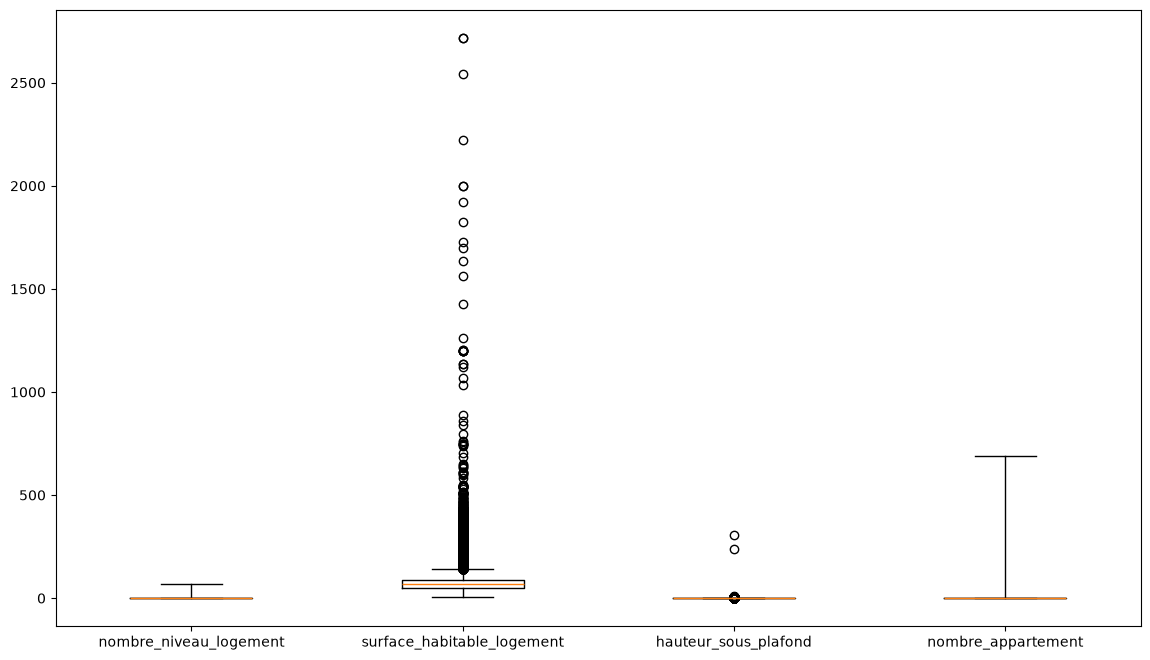

In [45]:
import matplotlib.pyplot as plt

from matplotlib.pyplot import boxplot

plt.figure(figsize=(14, 8))

boxplot(df.select_dtypes(exclude="str"), 
        tick_labels=df.select_dtypes(exclude="str").columns,
        autorange = True)

plt.show

On remarque que se basé uniquement sur l'interval interquantile nous ferais éliminé un grand nombre de dpe.
Ainsi, nous avons décidér d'être plus souple :
- Pour la première variable : nous gardons tout
- Pour la deuxième variable : nous posons un seil à 2500 
- Pour la troisième variable : nous fixon un seuil à 100 
- Pour la dernière variable : on garde tout

In [46]:
col = df.select_dtypes(exclude="str").columns
seuils = {
    col[0]: None,  # On conserve tout
    col[1]: 2500,
    col[2]: 100,
    col[3]: None   # On conserve tout
}

for col, seuil in seuils.items():
    if seuil is not None:
        ind= df[df[col] > seuil].index
        print(f"{col} : {len(ind)} DPE supprimés")
        index_suppr.extend(ind.tolist())
        df = df.drop(index=ind)

surface_habitable_logement : 3 DPE supprimés
hauteur_sous_plafond : 2 DPE supprimés


#### Suppression des index dans Y et ILLU

In [47]:
Y = Y.drop(index=index_suppr)
ILLU = ILLU.drop(index=index_suppr)

## Enregistrement des dataframe final

In [50]:
print(df.shape)
print(Y.shape)
print(ILLU.shape)

(58011, 19)
(58011, 16)
(58011, 2)


In [51]:
df.to_csv("Data/dpe_explicative.csv", index=True, encoding="utf-8")
Y.to_csv("Data/dpe_cible.csv", index=True, encoding="utf-8")
ILLU.to_csv("Data/dpe_illu.csv", index=True, encoding="utf-8")

#Document avec toutes les variables (pourrait se révéler utile)
pd.concat([data,ILLU,Y], axis=1, ignore_index=False).to_csv("Data/dpe.csv", index=True, encoding="utf-8")